In [1]:
import numpy as np
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split as tts 
from sklearn.svm import SVC
from sklearn.metrics  import confusion_matrix, accuracy_score
from sklearn.preprocessing import StandardScaler

In [2]:
data = load_wine(as_frame=True)
df = data.frame

display(df.shape)
display(df.head())

(178, 14)

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [3]:
X = df.drop("target",axis=1)
y = df["target"]

In [4]:
xtr, xt, ytr, yt = tts(X, y, test_size=0.2, random_state=42)

In [5]:
sc = StandardScaler()
xtr = sc.fit_transform(xtr)
xt = sc.transform(xt)

In [8]:
kernels = ["linear","poly","rbf"]

res = {}

for k in kernels: 
    model = SVC(kernel=k)
    model.fit(xtr, ytr)

    ypred = model.predict(xt)

    acc = accuracy_score(yt, ypred)
    res[k] = acc 

    print(k, "Accuracy: ", acc)


linear Accuracy:  0.9722222222222222
poly Accuracy:  0.9722222222222222
rbf Accuracy:  1.0


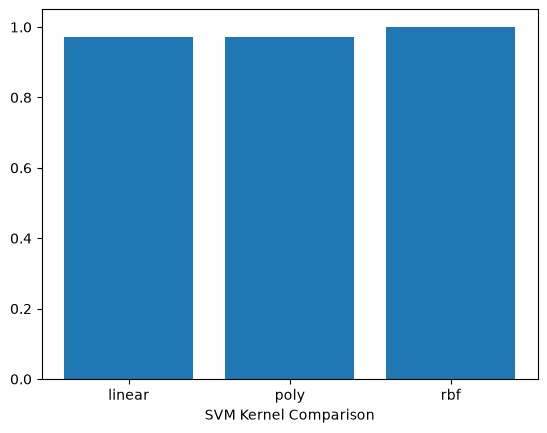

In [9]:
plt.bar(res.keys(), res.values())
plt.xlabel("SVM Kernels")
plt.xlabel("Accuracy")
plt.xlabel("SVM Kernel Comparison")
plt.show()

Best Kernel:  rbf
Confusion Matrix: 


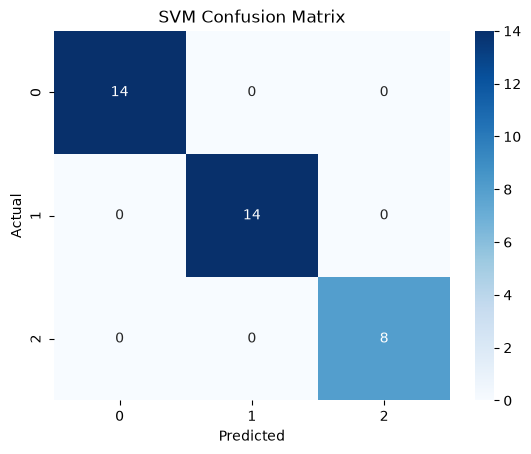

In [12]:
best = max(res, key=res.get)

model = SVC(kernel=best)
model.fit(xtr,ytr)

ypr = model.predict(xt)

print("Best Kernel: ", best)
print("Confusion Matrix: ")

cm = confusion_matrix(yt, ypr)
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("SVM Confusion Matrix")
plt.show()